# 06 - Modelo: regresión con train 2024, val 2025 y test 2026

Este es el notebook del modelo. Entrenamos una **regresión** que aprende con los datos de 2024, elegimos sus parámetros con 2025 y al final la probamos una sola vez con 2026. Usa la columna `particion` de gold (ver `config.py`):

| Conjunto | Fechas | Para qué |
|---|---|---|
| `train` | todo 2024 | La regresión aprende |
| `val` | todo 2025 | Elegimos `alfa` y si usamos la combinación hora x tipo de día |
| `test` | 2026 (hasta donde haya datos) | Lo probamos una sola vez, al final |

**¿Por qué un año entero para cada cosa?** Así el modelo ve todos los meses del año (también diciembre, con las fiestas y el fin de clases) antes de que lo probemos. Además val y test tienen las mismas épocas del año, así que se pueden comparar mejor, y val tiene 365 días, lo que da intervalos de confianza más angostos.

**El modelo.** Usamos **Ridge**, una regresión lineal con un castigo a los coeficientes grandes, sobre log(1 + pasajeros). Probamos dos versiones:

| Versión | Idea |
|---|---|
| `aditivo` | La hora y el tipo de día suman cada uno por su lado |
| `interacciones` | Además hay una columna por cada par hora x tipo de día, así cada tipo de día tiene su propia forma a lo largo del día |

Las dos versiones saben **qué tipo de día fue ayer**. En el EDA (sección 3.3) se ve por qué: un lunes no se parece al domingo, y el día después de un feriado no se parece al feriado. Por eso el rezago de 1 día entra dos veces, una normal y otra que vale 0 cuando ayer fue un tipo de día distinto a hoy, y además hay una columna con el cambio (por ejemplo "domingo a hábil"). La lluvia entra como log(1 + mm), para que una tormenta no pese tanto más que una lluvia común.

**Regla a superar.** La mediana de las 4 semanas anteriores (`mediana_4sem`). También calculamos `perfil_historico` y `regla_por_tipo_dia` (el perfil en feriados y la mediana el resto de los días) con las mismas filas.

**Cómo elegimos.** La regresión tiene dos "perillas" que hay que decidir antes de entrenar (se llaman **hiperparámetros**): `alfa` (qué tan fuerte es el castigo) y si usamos interacciones o no. Probamos unos pocos valores y nos quedamos con el que tiene menos error en val. Ojo: como elegimos mirando val, el error en val del ganador sale un poco más bajo de lo que va a ser en la realidad. El error de verdad lo vemos en test.

**Qué se guarda.** Los errores van a `resultados_modelos` con `etapa = 'modelo'` (validación) y `etapa = 'test'` (test).

## 0. Preparación

In [0]:
%run ./00_setup

# 00 - Preparar el proyecto

Este notebook deja todo listo para que los demás funcionen. Hace cuatro cosas:

1. Le dice a Python dónde está nuestro código (la carpeta `src/bondis`), para poder escribir `from bondis import ...`.
2. Crea en Databricks el lugar donde se guardan las tablas y los archivos (`bondis_stm.datos.raw`, definido en `config.py`).
3. Crea una carpeta para cada tipo de archivo (viajes, clima, etc.).
4. Muestra cómo dividimos los datos en train, val y test.

Se puede correr todas las veces que quieras. Si algo ya existe, no lo vuelve a crear ni lo borra.

No hace falta abrirlo a mano: los otros notebooks lo corren al principio con `%run ./00_setup`.

## 1. Encontrar nuestro código

Python solo puede importar código de las carpetas que conoce. Esta celda busca la carpeta del repositorio subiendo carpeta por carpeta hasta encontrar `src/bondis`, y la agrega a la lista de carpetas que Python conoce (`sys.path`).

## 2. Crear el catálogo, el esquema y el volume

Databricks ordena todo en tres niveles, como carpetas una dentro de otra:

- **Catálogo** (`bondis_stm`): la carpeta grande del proyecto.
- **Esquema** (`datos`): una subcarpeta donde van las tablas.
- **Volume** (`raw`): una carpeta para guardar archivos sueltos, como los ZIP y CSV que bajamos.


## 3. Crear una carpeta para cada tipo de archivo

| Carpeta | Qué va adentro |
|---|---|
| `viajes_zip/` | Los ZIP de viajes de cada mes, bajados a mano del portal de la Intendencia |
| `viajes/` | Los CSV de viajes, ya sacados de los ZIP |
| `clima/` | Lluvia y temperatura de cada hora |
| `calendario/` | Por ahora vacía. El calendario está escrito en `src/bondis/calendario.py` |
| `paros/` | Vacía. Al final no usamos paros, porque en los de estos años los ómnibus anduvieron normal (ver `calendario.py`) |

## 4. Revisar que todo esté bien

Muestra la versión de Spark, el usuario y cuántos archivos hay en cada carpeta. Sirve para ver de un vistazo si falta subir algo.

## 5. Cómo dividimos los datos

Usamos las fechas para dividir, no el azar, porque queremos predecir el futuro con el pasado. Un año entero para cada cosa:

| Conjunto | Fechas | Para qué se usa |
|---|---|---|
| `train` | todo 2024 | El modelo aprende con estos datos |
| `val` | todo 2025 | Comparamos y elegimos los parámetros de la regresión |
| `test` | 2026 (lo que haya) | Probamos el modelo elegido una sola vez, al final |

La fecha de fin **no** está incluida. Por eso siempre se filtra con `fecha >= inicio` y `fecha < fin`.

`train_final` es train + val juntos. Cuando ya elegimos el modelo, lo volvemos a entrenar con 2024 y 2025 antes de probarlo en 2026.

In [0]:
import importlib
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from bondis import metricas, modelos, variables

for _m in (metricas, modelos, variables):
    importlib.reload(_m)

spark.conf.set("spark.sql.session.timeZone", config.TIMEZONE)
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

OBJ = modelos.OBJETIVO
REFERENCIA = "mediana_4sem"
COL_PARTICION = "particion"   # train 2024, val 2025, test 2026 (ver config.py)

## 1. Datos

Usamos solo las filas completas (con todos los rezagos y el clima). Si gold todavía tiene la división vieja (val en 2024), el notebook avisa y hay que volver a correr el 03.

Test **no se baja todavía**. Se lee recién en la sección 9.

In [0]:
gold = variables.con_tipo_dia(spark.table(config.TABLE_GOLD)).where(F.col("fila_completa"))
primer_dia_val = gold.where(F.col(COL_PARTICION) == "val").agg(F.min("fecha")).first()[0]
assert primer_dia_val is not None and primer_dia_val.year == 2025, \
    "Gold tiene la división vieja (val en 2024). Volver a correr 03_features_gold."

leer, faltantes = modelos.columnas_a_leer(gold.columns)
if faltantes:
    print("Columnas opcionales que gold todavía no tiene (se siguen sin ellas):", faltantes)

base = gold.select(*leer, COL_PARTICION)
tamanos = variables.tamano_linea(gold.where(F.col(COL_PARTICION) == "train")).toPandas()


def bajar(particiones):
    """Pasa a pandas las filas de esos conjuntos y les agrega el tamaño de la línea."""
    df = (base.where(F.col(COL_PARTICION).isin(particiones)).drop(COL_PARTICION).toPandas()
          .merge(tamanos, on="linea", how="left")
          .fillna({"tamano_linea": "chica"}))
    return df


train_raw = bajar(["train"])
val_raw = bajar(["val"])

categorias = modelos.categorias_desde(train_raw)
train = modelos.preparar(train_raw, categorias)
val = modelos.preparar(val_raw, categorias)
del train_raw, val_raw   # para no ocupar memoria de más

for nombre, df in (("train", train), ("val", val)):
    print(f"{nombre:<6} {len(df):>10,} filas, {df['fecha'].nunique()} días "
          f"({df['fecha'].min().date()} a {df['fecha'].max().date()}), {df['linea'].nunique()} líneas")

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


train   1,100,208 filas, 338 días (2024-01-29 a 2024-12-31), 136 líneas
val     1,191,360 filas, 365 días (2025-01-01 a 2025-12-31), 136 líneas


## 2. Reglas para comparar

Las mismas reglas simples del 05, ahora calculadas con train = 2024 y medidas en val = 2025:
- `mediana_4sem`: la mediana de las 4 semanas anteriores (la que hay que superar).
- `perfil_historico`: el promedio de 2024 para la misma línea, hora y tipo de día.
- `regla_por_tipo_dia`: el perfil en feriados y la mediana el resto de los días.

In [0]:
PRED = {}   # para cada modelo, en qué columna de val está su predicción
for nombre, valores in modelos.referencias(train, val).items():
    val[f"pred_{nombre}"] = valores
    PRED[nombre] = f"pred_{nombre}"
    print(f"{nombre:<20} MAE val {np.abs(valores - val[OBJ]).mean():6.2f}")

mediana_4sem         MAE val  39.73
perfil_historico     MAE val  37.56
regla_por_tipo_dia   MAE val  36.22


## 3. Regresión Ridge

Probamos dos versiones (sin y con la combinación hora x tipo de día) y cinco valores de `alfa` (qué tan fuerte se castigan los coeficientes grandes). Nos quedamos con la que tenga menos MAE en val.

Train tiene todo 2024, con diciembre incluido, así que las columnas de fin de año (`es_vispera_navidad`, `es_fin_de_anio`, `es_semana_fiestas`) tienen días marcados en train y la regresión les puede dar un peso.

In [0]:
# Con un millón de filas, un alfa de 0,1 o de 100 casi no cambia nada (ver sección 6.2).
# Por eso los valores van mucho más arriba.
ALFAS = [1, 1_000, 10_000, 100_000, 1_000_000]

CANDIDATOS = {}   # para cada modelo: (tipo de modelo, sus parámetros)
for interacciones, etiqueta in ((False, "aditivo"), (True, "interacciones")):
    for alfa in ALFAS:
        CANDIDATOS[f"lineal_{etiqueta}_a{alfa}"] = ("lineal", {"interacciones": interacciones, "alfa": alfa})

ajustados = {}


def entrenar(candidatos):
    for nombre, (familia, params) in candidatos.items():
        modelo = modelos.crear_modelo(train.columns, familia, **params)
        pred, seg = modelos.ajustar_y_predecir(modelo, train, val)
        val[f"pred_{nombre}"] = pred
        PRED[nombre] = f"pred_{nombre}"
        ajustados[nombre] = modelo
        print(f"{nombre:<32} {seg:6.1f} s   MAE val {np.abs(pred - val[OBJ]).mean():6.2f}")


entrenar(CANDIDATOS)

lineal_aditivo_a1                   4.4 s   MAE val  32.45
lineal_aditivo_a1000                3.0 s   MAE val  32.56
lineal_aditivo_a10000               2.1 s   MAE val  33.71
lineal_aditivo_a100000              1.9 s   MAE val  41.00
lineal_aditivo_a1000000             1.8 s   MAE val 107.39
lineal_interacciones_a1             5.1 s   MAE val  32.24
lineal_interacciones_a1000          4.2 s   MAE val  32.27
lineal_interacciones_a10000         3.3 s   MAE val  33.45
lineal_interacciones_a100000        2.5 s   MAE val  40.72
lineal_interacciones_a1000000       2.1 s   MAE val 107.07


## 4. Resultados en validación

Se calcula igual que en el notebook 05: sumas por día, métricas a partir de esas sumas e intervalos del 95 % sorteando **semanas enteras** (tandas de 7 días seguidos). Todos los modelos usan las mismas semanas sorteadas. Por eso el intervalo de la **mejora** es el que dice si un modelo le gana de verdad a la mediana de 4 semanas.

In [0]:
est = modelos.estadisticos_por_dia(val, OBJ, PRED, grupos=["tipo_dia", "tamano_linea"])

globales = metricas.agregar_mejora(metricas.metricas(est), REFERENCIA)
intervalos = metricas.bootstrap_dias(est, REFERENCIA, n_rep=1000, seed=config.SEED, bloque=7)
globales = globales.merge(intervalos, on="modelo").sort_values("mae").reset_index(drop=True)


def fmt_intervalo(v, inf, sup, dec=1, pct=False):
    f = (lambda x: f"{100 * x:.{dec}f} %") if pct else (lambda x: f"{x:,.{dec}f}")
    return f"{f(v)} [{f(inf)} a {f(sup)}]"


def tabla_linda(g):
    return pd.DataFrame({
        "modelo": g["modelo"],
        "MAE [IC 95 %]": [fmt_intervalo(*x) for x in g[["mae", "mae_inf", "mae_sup"]].to_numpy()],
        "RMSE": g["rmse"].round(1),
        "R²": g["r2"].round(3),
        "WAPE": (100 * g["wape"]).round(1).astype(str) + " %",
        "sesgo": g["sesgo"].round(1),
        "mejora [IC 95 %]": [fmt_intervalo(*x, pct=True)
                             for x in g[["mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]].to_numpy()],
    })


print(tabla_linda(globales).to_string(index=False))

                       modelo         MAE [IC 95 %]  RMSE    R²   WAPE  sesgo               mejora [IC 95 %]
      lineal_interacciones_a1    32.2 [30.1 a 34.7]  70.0 0.966 12.9 %   -5.8       18.9 % [10.3 % a 28.5 %]
   lineal_interacciones_a1000    32.3 [30.2 a 34.8]  70.3 0.966 12.9 %   -6.7       18.8 % [10.3 % a 28.6 %]
            lineal_aditivo_a1    32.4 [30.3 a 34.8]  70.1 0.966 13.0 %   -7.4       18.3 % [10.2 % a 28.1 %]
         lineal_aditivo_a1000    32.6 [30.4 a 35.1]  70.7 0.965 13.0 %   -7.7        18.0 % [9.6 % a 28.0 %]
  lineal_interacciones_a10000    33.4 [31.1 a 36.2]  75.1 0.961 13.4 %   -9.2        15.8 % [6.5 % a 25.7 %]
        lineal_aditivo_a10000    33.7 [31.4 a 36.6]  75.7 0.960 13.5 %   -9.8        15.1 % [5.9 % a 25.0 %]
           regla_por_tipo_dia    36.2 [32.5 a 40.5]  83.5 0.951 14.5 %    0.9         8.8 % [3.2 % a 15.0 %]
             perfil_historico    37.6 [34.1 a 41.8]  81.4 0.954 15.0 %    9.9        5.5 % [-5.8 % a 15.6 %]
                 me

**Cómo leer la tabla.**
- Está ordenada de menor a mayor MAE. La **mejora** es 1 menos el MAE del modelo dividido el MAE de `mediana_4sem`. Un 0,10 es un 10 % menos de error.
- Si el intervalo de la mejora incluye el 0, no podemos decir que el modelo le gane a la mediana.
- Si el RMSE es mucho más grande que el MAE, hay pocos errores muy grandes (feriados, elecciones).
- El sesgo dice hacia dónde se equivoca: positivo, predice de más. Negativo, predice de menos. Los modelos con log suelen quedar con sesgo negativo, porque al deshacer el logaritmo la predicción se parece más a una mediana que a un promedio, y en estos datos la mediana es más baja que el promedio.

### 4.1 El mejor de cada versión

Miramos la mejor regresión sin interacciones y la mejor con interacciones, para ver cuánto aporta la combinación hora x tipo de día.

In [0]:
familia_de = {n: "lineal_" + n.split("_")[1] for n in CANDIDATOS}   # lineal_aditivo o lineal_interacciones
cand = globales[globales["modelo"].isin(CANDIDATOS)].copy()
cand["familia"] = cand["modelo"].map(familia_de)
mejores = cand.loc[cand.groupby("familia")["mae"].idxmin()].sort_values("mae")
print(mejores[["familia", "modelo", "mae", "rmse", "sesgo", "mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]]
      .round(3).to_string(index=False))

MEJOR = cand.sort_values("mae")["modelo"].iloc[0]
fila = globales.set_index("modelo").loc[MEJOR]
print(f"\nRegresión elegida en validación: {MEJOR}")
print(f"  MAE {fila['mae']:.1f}, mejora sobre {REFERENCIA}: {100 * fila['mejora_mae']:.1f} % "
      f"[{100 * fila['mejora_mae_inf']:.1f} % a {100 * fila['mejora_mae_sup']:.1f} %]")
if fila["mejora_mae_inf"] <= 0:
    print("  El intervalo de la mejora incluye el 0. En validación no se puede decir que le gane a la mediana de 4 semanas.")

             familia                  modelo    mae   rmse  sesgo  mejora_mae  mejora_mae_inf  mejora_mae_sup
lineal_interacciones lineal_interacciones_a1 32.239 70.015 -5.836       0.189           0.103           0.285
      lineal_aditivo       lineal_aditivo_a1 32.446 70.052 -7.407       0.183           0.102           0.281

Regresión elegida en validación: lineal_interacciones_a1
  MAE 32.2, mejora sobre mediana_4sem: 18.9 % [10.3 % a 28.5 %]


## 5. ¿Dónde mejora y dónde no?

La mediana de 4 semanas acierta casi siempre, así que un modelo solo puede ganar en los días que no se parecen a las semanas anteriores. Comparamos la mediana, las otras reglas, la mejor de cada versión y la elegida, separando por tipo de día.

In [0]:
MOSTRAR = [REFERENCIA, "perfil_historico", "regla_por_tipo_dia", *mejores["modelo"]]
MOSTRAR = list(dict.fromkeys(MOSTRAR))
orden = [m for m in globales["modelo"] if m in MOSTRAR]

por_tipo = metricas.agregar_mejora(metricas.metricas(est, por=["tipo_dia"]), REFERENCIA, por=["tipo_dia"])
dias_tipo = est.drop_duplicates(["fecha", "tipo_dia"]).groupby("tipo_dia")["fecha"].nunique().rename("días")
tipos = [t for t in variables.TIPOS_DIA if t in dias_tipo.index]

print("MAE por tipo de día (pasajeros por hora):")
t = por_tipo.pivot(index="modelo", columns="tipo_dia", values="mae").loc[orden, tipos].round(1)
print(pd.concat([dias_tipo[tipos].to_frame().T, t]).to_string(), "\n")

print("Sesgo por tipo de día (> 0: se pasa):")
print(por_tipo.pivot(index="modelo", columns="tipo_dia", values="sesgo").loc[orden, tipos].round(1).to_string())

MAE por tipo de día (pasajeros por hora):
tipo_dia                 hábil  sábado  domingo  turismo  feriado
días                     249.0    50.0     51.0      7.0      8.0
lineal_interacciones_a1   35.7    22.9     20.9     53.8     36.3
lineal_aditivo_a1         36.0    23.2     21.3     50.4     34.5
regla_por_tipo_dia        38.5    25.2     21.6    122.9     51.7
perfil_historico          42.0    26.1     23.2     49.7     51.7
mediana_4sem              38.5    25.2     21.6    122.9    211.6 

Sesgo por tipo de día (> 0: se pasa):
tipo_dia                 hábil  sábado  domingo  turismo  feriado
modelo                                                           
lineal_interacciones_a1   -3.6    -8.6     -7.4    -33.4    -23.9
lineal_aditivo_a1         -6.6    -9.2     -9.2    -10.6     -7.4
regla_por_tipo_dia        -1.9    -0.3     -1.7    119.3      6.5
perfil_historico          11.2     8.3      7.0      3.4      6.5
mediana_4sem              -1.9    -0.3     -1.7    119.3    

### 5.1 Por tamaño de línea

El MAE lo deciden las líneas grandes. El WAPE, como es un porcentaje, sirve para comparar grupos de distinto tamaño.

In [0]:
por_tam = metricas.metricas(est, por=["tamano_linea"])
grupos_tam = [g for g in ["grande", "mediana", "chica"] if g in set(por_tam["tamano_linea"])]
for col, titulo in (("mae", "MAE"), ("wape", "WAPE")):
    t = por_tam.pivot(index="modelo", columns="tamano_linea", values=col).loc[orden, grupos_tam]
    print(f"{titulo} por tamaño de línea:")
    print((t * 100).round(1).astype(str).add(" %").to_string() if col == "wape" else t.round(1).to_string(), "\n")

MAE por tamaño de línea:
tamano_linea             grande  mediana  chica
modelo                                         
lineal_interacciones_a1    79.8     53.6   13.7
lineal_aditivo_a1          80.1     54.0   13.8
regla_por_tipo_dia         88.9     61.6   15.1
perfil_historico           93.0     63.5   15.6
mediana_4sem               97.8     68.0   16.4 

WAPE por tamaño de línea:
tamano_linea             grande mediana   chica
modelo                                         
lineal_interacciones_a1  11.3 %  12.1 %  17.8 %
lineal_aditivo_a1        11.3 %  12.2 %  17.9 %
regla_por_tipo_dia       12.6 %  14.0 %  19.6 %
perfil_historico         13.2 %  14.4 %  20.3 %
mediana_4sem             13.8 %  15.4 %  21.2 % 



### 5.2 Día por día

El MAE de cada día de validación para la mediana de 4 semanas y para el modelo elegido. Las líneas grises punteadas son días especiales y las rojas son días en que empiezan o terminan las clases.

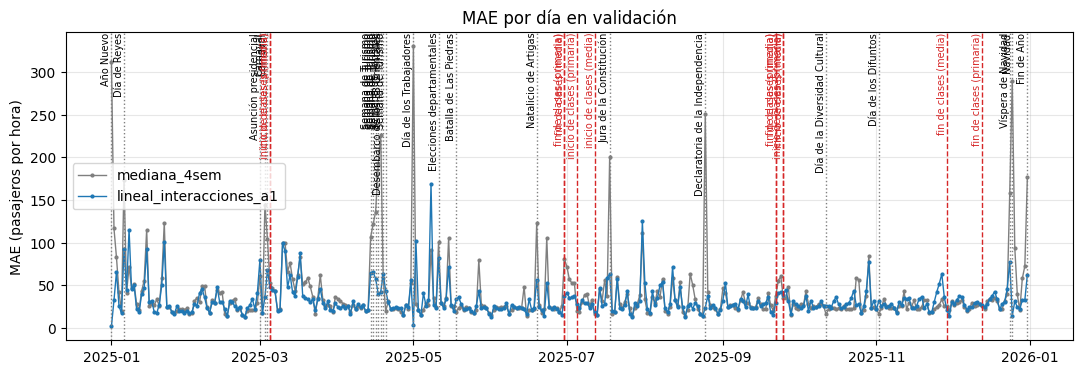

Los 10 días con más error de lineal_interacciones_a1:
     fecha tipo_dia nombre_dia_especial   mae  sesgo  mae_referencia
2025-05-08    hábil                None 169.4 -169.2            91.6
2025-07-31    hábil                None 125.2  120.9           111.6
2025-01-08    hábil                None 115.2 -114.8            72.1
2025-05-02    hábil                None 102.1  -98.1            28.6
2025-01-22    hábil                None 100.9 -100.8           123.5
2025-03-10    hábil                None  99.7  -95.9            99.1
2025-01-06    hábil        Día de Reyes  93.1   86.5           174.0
2025-01-15    hábil                None  92.4  -92.0           115.1
2025-03-11    hábil                None  89.8  -87.4            99.7
2025-03-17    hábil                None  87.6  -80.6            83.1


In [0]:
info_dias = (val[["fecha", "tipo_dia", "nombre_dia_especial", "clases_primaria", "clases_media"]]
             .drop_duplicates("fecha"))
info_dias = info_dias.assign(tipo_dia=info_dias["tipo_dia"].astype(str))

diario = metricas.metricas(est.groupby(["modelo", "fecha"], as_index=False)[metricas.ESTADISTICOS].sum(), por=["fecha"])
fig, ax = plt.subplots()
for m, color in ((REFERENCIA, "tab:gray"), (MEJOR, "tab:blue")):
    s = diario[diario["modelo"] == m].sort_values("fecha")
    ax.plot(s["fecha"], s["mae"], marker=".", ms=4, lw=1, label=m, color=color)
tope = ax.get_ylim()[1]
for _, d in info_dias.dropna(subset=["nombre_dia_especial"]).iterrows():
    ax.axvline(d["fecha"], color="gray", ls=":", lw=1)
    ax.text(d["fecha"], tope, d["nombre_dia_especial"], rotation=90, va="top", ha="right", fontsize=7)

cal = info_dias.sort_values("fecha").set_index("fecha")[["clases_primaria", "clases_media"]]
for nivel in ("primaria", "media"):
    c = cal[f"clases_{nivel}"].astype(int).diff()
    for f, v in c[c != 0].dropna().items():
        etiqueta = f"{'inicio' if v > 0 else 'fin'} de clases ({nivel})"
        ax.axvline(f, color="tab:red", ls="--", lw=1)
        ax.text(f, tope, etiqueta, rotation=90, va="top", ha="right", fontsize=7, color="tab:red")

ax.set(title="MAE por día en validación", ylabel="MAE (pasajeros por hora)")
ax.legend(loc="center left")
plt.show()

peores = (diario[diario["modelo"] == MEJOR].nlargest(10, "mae")
          .merge(info_dias, on="fecha")[["fecha", "tipo_dia", "nombre_dia_especial", "mae", "sesgo"]])
ref_dia = diario[diario["modelo"] == REFERENCIA].set_index("fecha")["mae"].rename("mae_referencia")
peores = peores.merge(ref_dia, left_on="fecha", right_index=True)
print(f"Los 10 días con más error de {MEJOR}:")
print(peores.round(1).to_string(index=False))

### 5.3 Mes por mes

Con un año entero en val podemos ver en qué épocas la regresión le gana a la mediana y en cuáles no. Lo esperable es que gane en los meses con más días distintos a las semanas anteriores: diciembre (fiestas y fin de clases), marzo (comienzo de clases) y los meses con feriados largos como Carnaval y Turismo.

MAE por mes:
modelo  lineal_interacciones_a1  lineal_aditivo_a1  regla_por_tipo_dia  perfil_historico  mediana_4sem
mes                                                                                                   
1                          37.9               37.8                48.5              71.1          56.1
2                          27.5               28.6                27.6              47.2          27.6
3                          42.9               42.6                47.6              32.8          52.6
4                          32.0               31.7                48.3              34.7          48.3
5                          35.7               36.1                35.0              32.1          43.2
6                          25.0               24.9                31.1              35.0          31.1
7                          33.9               34.3                36.3              35.3          41.8
8                          29.7               31.6          

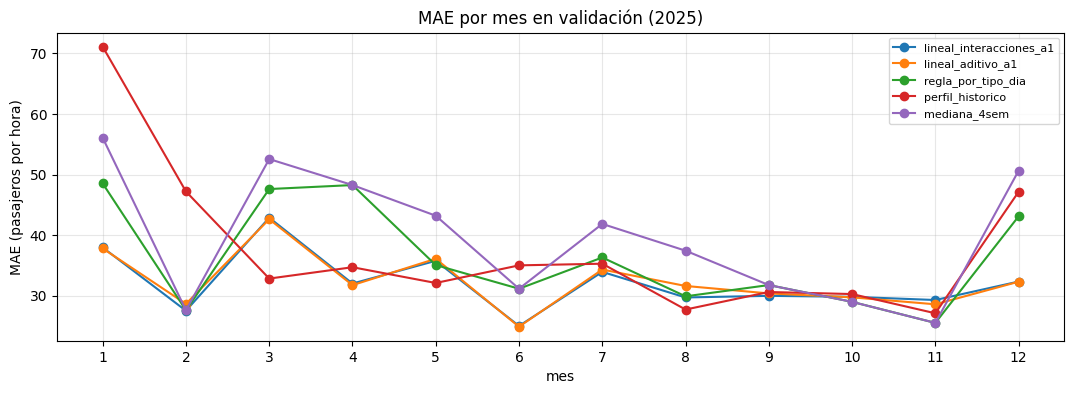

IOStream.flush timed out


In [0]:
est_mes = est.assign(mes=est["fecha"].dt.month)
por_mes = metricas.metricas(est_mes, por=["mes"])
t = por_mes.pivot(index="mes", columns="modelo", values="mae")[orden]
print("MAE por mes:")
print(t.round(1).to_string())

fig, ax = plt.subplots()
for m in orden:
    ax.plot(t.index, t[m], marker="o", label=m)
ax.set(title="MAE por mes en validación (2025)", xlabel="mes", ylabel="MAE (pasajeros por hora)", xticks=range(1, 13))
ax.legend(fontsize=8)
plt.show()

## 6. Error en train y en validación: ¿subajuste o sobreajuste?

Hay dos formas de que un modelo salga mal:

- **Subajuste**: el modelo es demasiado simple y no aprende ni siquiera con los datos que vio. Es como estudiar solo el índice del libro. El error es **alto en train y también alto en validación**.
- **Sobreajuste**: el modelo se aprende de memoria los detalles de train, incluso los que fueron casualidad, y después no le va bien con datos nuevos. Es como aprenderse las respuestas del práctico sin entender: en el práctico te va perfecto y en el examen no. El error en train es **mucho más bajo** que en validación.

**Cuidado con una trampa de nuestro problema.** Validación no es una parte al azar de train, es otro año (2025). Entonces el error en validación puede ser distinto al de train solo porque cambió algo de un año al otro (más o menos pasajeros, líneas que cambiaron), no porque el modelo esté sobreajustado.

Para separar las dos cosas usamos la mediana de 4 semanas como "termómetro". Esa regla no aprende nada, así que no puede sobreajustar. Si su error cambia entre train y validación, es solo por el cambio de año. Entonces calculamos el **exceso**:

$$\text{exceso} = \frac{\text{MAE val del modelo} \,/\, \text{MAE train del modelo}}{\text{MAE val de la mediana} \,/\, \text{MAE train de la mediana}}$$

- Exceso cerca de 1: la diferencia entre train y validación se explica por el cambio de año. No hay sobreajuste.
- Exceso bastante mayor que 1: el modelo empeora en validación más que la mediana. Hay sobreajuste.

### 6.1 Error en train y en validación de cada modelo

El MAE de train se mide sobre una muestra de 200 mil filas, para que sea más rápido.

In [0]:
N_TRAIN_CURVAS = 200_000
sub_train = train.sample(n=min(N_TRAIN_CURVAS, len(train)), random_state=config.SEED)
ref_tr = modelos.mae(sub_train[OBJ], sub_train[modelos.REFERENCIA])
ref_va = modelos.mae(val[OBJ], val[modelos.REFERENCIA])
brecha_ref = ref_va / ref_tr
print(f"{REFERENCIA}: MAE train {ref_tr:.2f}, MAE val {ref_va:.2f}, cociente val/train {brecha_ref:.2f}\n")

diag = modelos.error_train_val(ajustados, list(CANDIDATOS), train, val, n_train=N_TRAIN_CURVAS, semilla=config.SEED)
diag["brecha"] = diag["mae_val"] - diag["mae_train"]
diag["val/train"] = diag["mae_val"] / diag["mae_train"]
diag["exceso"] = diag["val/train"] / brecha_ref
diag["mejora_en_train"] = 1 - diag["mae_train"] / ref_tr
print(diag.sort_values("mae_val").round(3).to_string(index=False))

mediana_4sem: MAE train 37.84, MAE val 39.73, cociente val/train 1.05

                       modelo  mae_train  mae_val  brecha  val/train  exceso  mejora_en_train
      lineal_interacciones_a1     31.971   32.239   0.267      1.008   0.960            0.155
   lineal_interacciones_a1000     32.073   32.273   0.200      1.006   0.958            0.152
            lineal_aditivo_a1     32.025   32.446   0.422      1.013   0.965            0.154
         lineal_aditivo_a1000     32.241   32.561   0.320      1.010   0.962            0.148
  lineal_interacciones_a10000     33.550   33.448  -0.102      0.997   0.950            0.113
        lineal_aditivo_a10000     33.757   33.715  -0.042      0.999   0.951            0.108
 lineal_interacciones_a100000     41.208   40.721  -0.487      0.988   0.941           -0.089
       lineal_aditivo_a100000     41.488   41.003  -0.484      0.988   0.941           -0.096
lineal_interacciones_a1000000    112.490  107.071  -5.419      0.952   0.907       

**Cómo leer la tabla.** `mejora_en_train` dice cuánto le gana el modelo a la mediana en los datos que vio. Si es baja, el modelo no logra aprender ni siquiera train (subajuste, o simplemente no hay mucho más para aprender). Un `exceso` bastante mayor que 1 indica sobreajuste. Si el `exceso` está cerca de 1 y la mejora en train se parece a la mejora en validación, el modelo funciona igual en los dos años.

### 6.2 El error según `alfa`

`alfa` es el castigo a los coeficientes grandes. Con `alfa` muy grande el modelo queda demasiado rígido y no aprende (subajuste). Con `alfa` muy chico es casi una regresión lineal común y podría sobreajustar, aunque con tantas filas y pocas columnas casi no pasa.

Ojo con la escala. Ridge compara el castigo contra la suma de los errores de **todas** las filas, que son más o menos un millón. Por eso un `alfa` de 0,1 o de 100 es chiquito al lado de esa suma y da prácticamente el mismo modelo. Para que se note algo hay que ir a valores de miles o millones. Si la curva sale plana en los valores chicos y sube recién en los grandes, quiere decir que el castigo no hacía falta.

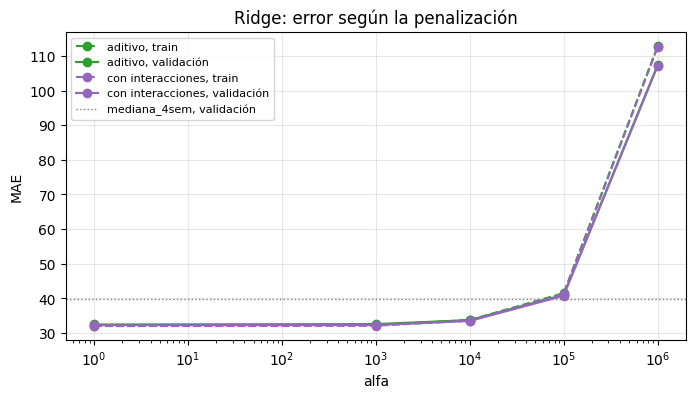

         variante    alfa  mae_train  mae_val  brecha  exceso
          aditivo       1     32.025   32.446   0.422   0.965
          aditivo    1000     32.241   32.561   0.320   0.962
          aditivo   10000     33.757   33.715  -0.042   0.951
          aditivo  100000     41.488   41.003  -0.484   0.941
          aditivo 1000000    112.831  107.390  -5.441   0.906
con interacciones       1     31.971   32.239   0.267   0.960
con interacciones    1000     32.073   32.273   0.200   0.958
con interacciones   10000     33.550   33.448  -0.102   0.950
con interacciones  100000     41.208   40.721  -0.487   0.941
con interacciones 1000000    112.490  107.071  -5.419   0.907


In [0]:
lin = diag[diag["modelo"].isin([n for n, c in CANDIDATOS.items() if c[0] == "lineal"])].copy()
lin["alfa"] = lin["modelo"].map(lambda n: CANDIDATOS[n][1]["alfa"])
lin["variante"] = lin["modelo"].map(lambda n: "con interacciones" if CANDIDATOS[n][1]["interacciones"] else "aditivo")

fig, ax = plt.subplots(figsize=(8, 4))
for (variante, g), color in zip(lin.groupby("variante"), ("tab:green", "tab:purple")):
    g = g.sort_values("alfa")
    ax.plot(g["alfa"], g["mae_train"], ls="--", marker="o", color=color, label=f"{variante}, train")
    ax.plot(g["alfa"], g["mae_val"], ls="-", marker="o", color=color, label=f"{variante}, validación")
ax.axhline(ref_va, color="gray", ls=":", lw=1, label=f"{REFERENCIA}, validación")
ax.set(xscale="log", xlabel="alfa", ylabel="MAE", title="Ridge: error según la penalización")
ax.legend(fontsize=8)
plt.show()
print(lin.sort_values(["variante", "alfa"])[["variante", "alfa", "mae_train", "mae_val", "brecha", "exceso"]].round(3).to_string(index=False))

### 6.3 Curva de aprendizaje: ¿más datos ayudarían?

Volvemos a entrenar el modelo elegido con una parte cada vez más grande de los **días** de train (10 %, 25 %, 50 %, 75 % y 100 %). Se sortean días enteros, no filas sueltas. Cada vez medimos el error en esos mismos días y en validación.

- Si las dos curvas se juntan y quedan **planas y altas**: más datos no ayudan. El problema es el modelo (subajuste) o que hay cosas que no se pueden predecir.
- Si hay una **distancia entre las curvas que se achica** al agregar datos: más datos ayudarían, y el modelo hoy está un poco sobreajustado.
- Cuidado: con pocos días, train no tiene todos los tipos de día. Por eso, del lado izquierdo del gráfico la distancia mezcla sobreajuste con falta de ejemplos.

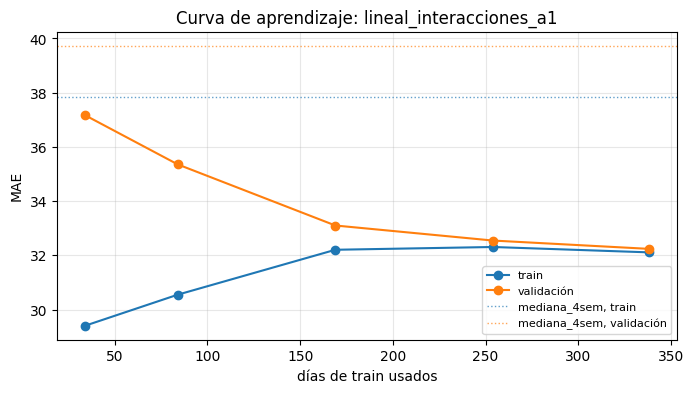

 fraccion  dias   filas  mae_train  mae_val  segundos
     0.10    34  110688     29.404   37.166     0.393
     0.25    84  273312     30.549   35.352     1.053
     0.50   169  550080     32.205   33.100     2.445
     0.75   254  826896     32.307   32.545     4.199
     1.00   338 1100208     32.109   32.239     5.140


In [0]:
familia_m, params_m = CANDIDATOS[MEJOR]
curva_ap = modelos.curva_aprendizaje(
    lambda: modelos.crear_modelo(train.columns, familia_m, **params_m),
    train, val, fracciones=(0.1, 0.25, 0.5, 0.75, 1.0), semilla=config.SEED)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva_ap["dias"], curva_ap["mae_train"], marker="o", color="tab:blue", label="train")
ax.plot(curva_ap["dias"], curva_ap["mae_val"], marker="o", color="tab:orange", label="validación")
ax.axhline(ref_tr, color="tab:blue", ls=":", lw=1, alpha=0.7, label=f"{REFERENCIA}, train")
ax.axhline(ref_va, color="tab:orange", ls=":", lw=1, alpha=0.7, label=f"{REFERENCIA}, validación")
ax.set(xlabel="días de train usados", ylabel="MAE", title=f"Curva de aprendizaje: {MEJOR}")
ax.legend(fontsize=8)
plt.show()
print(curva_ap.round(3).to_string(index=False))

**Qué mirar en la sección 6.** Si algún modelo sobreajusta (exceso bastante mayor que 1, o error de validación que sube cuando `alfa` es muy chico), si hay subajuste (error alto en train y poca mejora sobre la mediana) y si más datos ayudarían. Train tiene un solo año, así que de cada día especial (Navidad, Carnaval, Turismo) hay un solo ejemplo. Al volver a entrenar con train + val para test, el modelo ve dos de cada uno.

## 7. ¿Qué variables usa más el modelo?

Usamos la **importancia por permutación**. La idea es simple: tomamos una muestra de validación y **mezclamos al azar** los valores de un grupo de variables, como si barajáramos esa columna. Así esa variable deja de tener sentido. Después medimos cuánto sube el MAE:
- Si sube mucho, el modelo dependía mucho de esa variable.
- Si casi no sube, el modelo no la usaba mucho.

Las variables se mezclan en grupos porque varias dicen casi lo mismo (los rezagos, el promedio y la mediana de 4 semanas). Si mezcláramos una sola, el modelo usaría las otras y parecería que no importa.

Es una medida aproximada. No dice que una variable **cause** más pasajeros. Y si un grupo da importancia baja, puede ser que no sirva o que otro grupo diga lo mismo.

MAE de lineal_interacciones_a1 en la muestra sin desordenar: 32.26

                     grupo  mae_permutado  aumento_mae  aumento_pct
      rezagos de pasajeros        340.057      307.796        9.541
  tipo de día (hoy y ayer)         57.064       24.803        0.769
feriados y días especiales         38.578        6.317        0.196
                      hora         36.736        4.475        0.139
                     clima         35.652        3.391        0.105
                fin de año         34.614        2.353        0.073
                    clases         33.558        1.297        0.040
                     línea         32.352        0.091        0.003


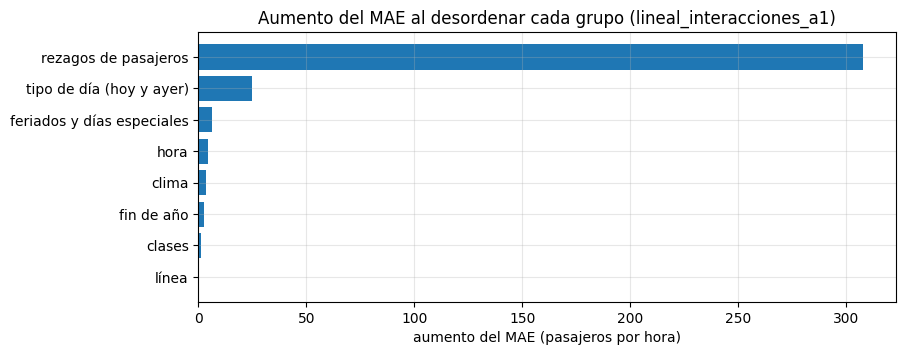

In [0]:
muestra = val.sample(n=min(100_000, len(val)), random_state=config.SEED)
imp = modelos.importancia_por_grupos(ajustados[MEJOR], muestra, modelos.grupos_de_variables(val.columns),
                                     n_rep=3, seed=config.SEED)
print(f"MAE de {MEJOR} en la muestra sin desordenar: {imp.attrs['mae_base']:.2f}\n")
print(imp[["grupo", "mae_permutado", "aumento_mae", "aumento_pct"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(imp["grupo"][::-1], imp["aumento_mae"][::-1], color="tab:blue")
ax.set(title=f"Aumento del MAE al desordenar cada grupo ({MEJOR})", xlabel="aumento del MAE (pasajeros por hora)")
plt.show()

### 7.1 Los coeficientes de la regresión

Una ventaja de la regresión es que se pueden mirar los coeficientes. Las variables numéricas están estandarizadas, así que sus coeficientes se pueden comparar entre sí: dicen cuánto cambia log(1 + pasajeros) cuando la variable sube un desvío. En las de sí o no, exp(coef) - 1 es más o menos cuánto cambian los pasajeros en porcentaje.

Igual que con la permutación, esto no dice que una variable **cause** más pasajeros. Si dos variables dicen casi lo mismo, el peso se reparte entre ellas.

In [0]:
ridge = ajustados[MEJOR].regressor_.named_steps["ridge"]
nombres = ajustados[MEJOR].regressor_.named_steps["pre"].get_feature_names_out()
coefs = pd.DataFrame({"variable": nombres, "coef": ridge.coef_})
numericas = coefs[coefs["variable"].str.startswith("num__")].copy()
numericas["variable"] = numericas["variable"].str.replace("num__", "", regex=False)
numericas = numericas.reindex(numericas["coef"].abs().sort_values(ascending=False).index)
print(f"Coeficientes de las variables numéricas y de sí o no ({MEJOR}):")
print(numericas.round(4).to_string(index=False))

Coeficientes de las variables numéricas y de sí o no (lineal_interacciones_a1):
                        variable    coef
      log_pasajeros_mediana_4sem  2.0455
            log_pasajeros_lag_1d  0.2135
            log_pasajeros_lag_7d  0.1638
             es_dia_sin_servicio -0.1292
                 es_no_laborable -0.0788
                      es_turismo -0.0694
                      es_feriado -0.0510
                  es_fin_de_anio -0.0442
               es_semana_fiestas -0.0431
              es_vispera_navidad -0.0385
                temperatura_pron  0.0378
           log_lag_1d_mismo_tipo  0.0344
                     es_eleccion  0.0263
          log_lluvia_pron_dia_mm -0.0251
                    clases_media  0.0246
log_pasajeros_linea_dia_anterior  0.0206
              log_lluvia_pron_mm -0.0194
                     es_carnaval -0.0140
                     llueve_pron -0.0121
                 clases_primaria  0.0035


## 8. Guardar los resultados de validación

Se guardan en `resultados_modelos` con `etapa = 'modelo'`. Si se vuelve a correr, se reemplazan solo esas filas. Se guardan las reglas y todas las versiones de la regresión. `parametros` dice con qué valores se entrenó cada una y `seleccionado` marca la elegida.

In [0]:
COLUMNAS_RESULTADOS = ["etapa", "conjunto", "modelo", "referencia", "filas", "mae", "mae_inf", "mae_sup", "rmse",
                       "rmse_inf", "rmse_sup", "r2", "wape", "sesgo", "mejora_mae", "mejora_mae_inf",
                       "mejora_mae_sup", "parametros", "seleccionado", "fecha_ejecucion"]
NO_NUMERICAS = ("etapa", "conjunto", "modelo", "referencia", "fecha_ejecucion", "filas", "parametros", "seleccionado")


def guardar(tabla, etapa, conjunto, parametros, elegido):
    salida = tabla.assign(
        etapa=etapa, conjunto=conjunto, referencia=REFERENCIA,
        parametros=[parametros.get(m, "regla simple") for m in tabla["modelo"]],
        seleccionado=(tabla["modelo"] == elegido).to_numpy(),
        fecha_ejecucion=datetime.now().strftime("%Y-%m-%d %H:%M"),
    )
    salida = salida[COLUMNAS_RESULTADOS].astype({c: "float64" for c in COLUMNAS_RESULTADOS if c not in NO_NUMERICAS})
    escritor = spark.createDataFrame(salida).write.format("delta").mode("overwrite").option("mergeSchema", "true")
    if spark.catalog.tableExists(config.TABLE_RESULTADOS):
        escritor.option("replaceWhere", f"etapa = '{etapa}'").saveAsTable(config.TABLE_RESULTADOS)
    else:
        escritor.saveAsTable(config.TABLE_RESULTADOS)
    print(spark.table(config.TABLE_RESULTADOS).where(F.col("etapa") == etapa)
          .select("modelo", "mae", "rmse", "r2", "mejora_mae", "seleccionado").toPandas().round(3).to_string(index=False))


PARAMETROS = {m: f"{c[0]} {c[1]}" for m, c in CANDIDATOS.items()}
guardar(globales, "modelo", "val", PARAMETROS, MEJOR)

                       modelo     mae    rmse    r2  mejora_mae  seleccionado
      lineal_interacciones_a1  32.239  70.015 0.966       0.189          True
   lineal_interacciones_a1000  32.273  70.293 0.966       0.188         False
            lineal_aditivo_a1  32.446  70.052 0.966       0.183         False
         lineal_aditivo_a1000  32.561  70.736 0.965       0.180         False
  lineal_interacciones_a10000  33.448  75.071 0.961       0.158         False
        lineal_aditivo_a10000  33.715  75.698 0.960       0.151         False
           regla_por_tipo_dia  36.224  83.542 0.951       0.088         False
             perfil_historico  37.560  81.402 0.954       0.055         False
                 mediana_4sem  39.730 100.903 0.929       0.000         False
 lineal_interacciones_a100000  40.721  94.911 0.937      -0.025         False
       lineal_aditivo_a100000  41.003  95.760 0.936      -0.032         False
lineal_interacciones_a1000000 107.071 220.948 0.660      -1.695 

## 9. Test (2026): se corre UNA sola vez

Pasos:
1. Volver a entrenar la regresión elegida en la sección 4 con **train + val** (2024 y 2025, `config.PARTICION_TRAIN_FINAL`), con los mismos parámetros (`MEJOR`, elegida en la sección 4.1). El `alfa` no se cambia aunque ahora haya más o menos el doble de filas. Como Ridge suma el castigo contra el error de todas las filas, con más filas el mismo `alfa` castiga menos, y está bien que sea así: con más datos el modelo necesita menos castigo.
2. Predecir 2026 y calcular las reglas simples con las mismas filas.
3. Medir el error igual que antes y guardarlo con `etapa = 'test'`.

**Importante.** Después de mirar test no se puede volver a cambiar el modelo, porque sería hacer trampa (estaríamos eligiendo con test). Por eso esta parte está apagada. Cuando ya estemos conformes con lo de val, poner `EVALUAR_EN_TEST = True` y correr solo esta celda.

2026 todavía puede no estar completo. El test va hasta el último día con datos y el resultado hay que leerlo sabiendo qué meses entraron.

In [0]:
EVALUAR_EN_TEST = False

if not EVALUAR_EN_TEST:
    print("Test apagado. Poner EVALUAR_EN_TEST = True cuando el modelo ya esté elegido.")
else:
    familia, params = CANDIDATOS[MEJOR]
    del train, val   # liberamos memoria antes de bajar los datos grandes

    final_raw = bajar(["train", "val"])
    test_raw = bajar(["test"])
    cat_final = modelos.categorias_desde(final_raw)
    train_final = modelos.preparar(final_raw, cat_final)
    test = modelos.preparar(test_raw, cat_final)
    del final_raw, test_raw
    print(f"train final: {len(train_final):,} filas ({train_final['fecha'].min().date()} a {train_final['fecha'].max().date()})")
    print(f"test:        {len(test):,} filas ({test['fecha'].min().date()} a {test['fecha'].max().date()}), "
          f"{test['fecha'].nunique()} días")

    PRED_TEST = {}
    for nombre, valores in modelos.referencias(train_final, test).items():
        test[f"pred_{nombre}"] = valores
        PRED_TEST[nombre] = f"pred_{nombre}"

    modelo_final = modelos.crear_modelo(train_final.columns, familia, **params)
    pred, seg = modelos.ajustar_y_predecir(modelo_final, train_final, test)
    test[f"pred_{MEJOR}"] = pred
    PRED_TEST[MEJOR] = f"pred_{MEJOR}"
    print(f"Entrenado en {seg:.1f} s")

    est_test = modelos.estadisticos_por_dia(test, OBJ, PRED_TEST, grupos=["tipo_dia", "tamano_linea"])
    glob_test = metricas.agregar_mejora(metricas.metricas(est_test), REFERENCIA)
    glob_test = (glob_test.merge(metricas.bootstrap_dias(est_test, REFERENCIA, n_rep=1000, seed=config.SEED, bloque=7), on="modelo")
                 .sort_values("mae").reset_index(drop=True))
    print()
    print(tabla_linda(glob_test).to_string(index=False))

    por_tipo_test = metricas.metricas(est_test, por=["tipo_dia"])
    tipos_test = [t for t in variables.TIPOS_DIA if t in set(por_tipo_test["tipo_dia"])]
    print("\nMAE por tipo de día en test:")
    print(por_tipo_test.pivot(index="modelo", columns="tipo_dia", values="mae")[tipos_test].round(1).to_string())

    guardar(glob_test, "test", "test", PARAMETROS, MEJOR)

Test apagado. Poner EVALUAR_EN_TEST = True cuando el modelo ya esté elegido.
